# Criar subdatasets para cada distrito

In [ ]:
# Reiniciar o programa
#import os
#os.kill(os.getpid(),9)

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import plotly.express as px
import pickle
from tqdm import tqdm

# Carregar os dados normalizados
X = pd.read_csv("input_d.csv")
y = pd.read_csv("output_d.csv")

X['ID'] = [i for i in range(len(X))]


In [8]:
X

,built_in,tipology,amenities,m2,m2_util,timestamp,energetic_efficiency,house_type,latitude,longitude,latitude_norm,longitude_norm,ID
0,True,0.142857,True,0.16,0.16,1.712327e+09,True,0.142857,38.845392,-7.589737,0.692057,-0.070647,0
1,2012,0.285714,Swimming pool,0.12,0.12,1.712088e+09,a,0.285714,37.508494,-8.704422,0.668239,-0.081023,1
2,2006,0.357143,True,0.16,0.10,1.712170e+09,f,0.428571,38.449443,-7.479972,0.685003,-0.069626,2
3,2015,0.357143,Swimming pool,0.20,0.20,1.711647e+09,True,0.285714,37.764840,-25.603582,0.672806,-0.238325,3
4,1978,0.142857,True,0.04,0.04,1.712326e+09,True,0.428571,38.845392,-7.589737,0.692057,-0.070647,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4484,True,0.214286,True,0.26,0.12,1.712090e+09,d,0.285714,38.832497,-7.507994,0.691827,-0.069886,4484
4485,True,0.214286,Garden,0.10,0.08,1.712089e+09,True,0.142857,38.250758,-7.900406,0.681463,-0.073539,4485
4486,True,0.285714,True,0.22,0.22,1.712086e+09,True,0.571429,37.477889,-8.550128,0.667694,-0.079587,4486
4487,True,0.285714,Garden,0.26,0.26,1.712089e+09,f,0.571429,37.751592,-8.412954,0.672570,-0.078310,4487


In [9]:
y

,Price_Real,Price_norm
0,68000,0.004533
1,550000,0.036667
2,269000,0.017933
3,850000,0.056667
4,99800,0.006653
...,...,...
4484,37000,0.002467
4485,75000,0.005000
4486,145000,0.009667
4487,350000,0.023333


In [10]:
# obter lista de coordenadas 
def obter_lat_long(X_train):
    data_train = []
    for lat, lon in zip(X_train['latitude'], X_train['longitude']):
        coord = [lat, lon]
        data_train.append(coord)
    data_train = np.array(data_train)
    return data_train

data_ = obter_lat_long(X)

## K-means

In [5]:
# kmeans --> 1 iteração

distrito = pd.read_csv('distritos_centro.csv')
distrito['ID'] = [i for i in range(len(distrito))]

def kmeans_1(distrito, data_train, X_train): 
    
    centroides = obter_lat_long(distrito)
    labels = np.argmin(np.array([np.linalg.norm(data_train - centroide, axis=1) for centroide in centroides]), axis=0)
    X_train['Centroide'] = labels
    return labels


kmeans_1(distrito, data_, X)

array([13, 14, 15, ..., 17, 16, 15], dtype=int64)

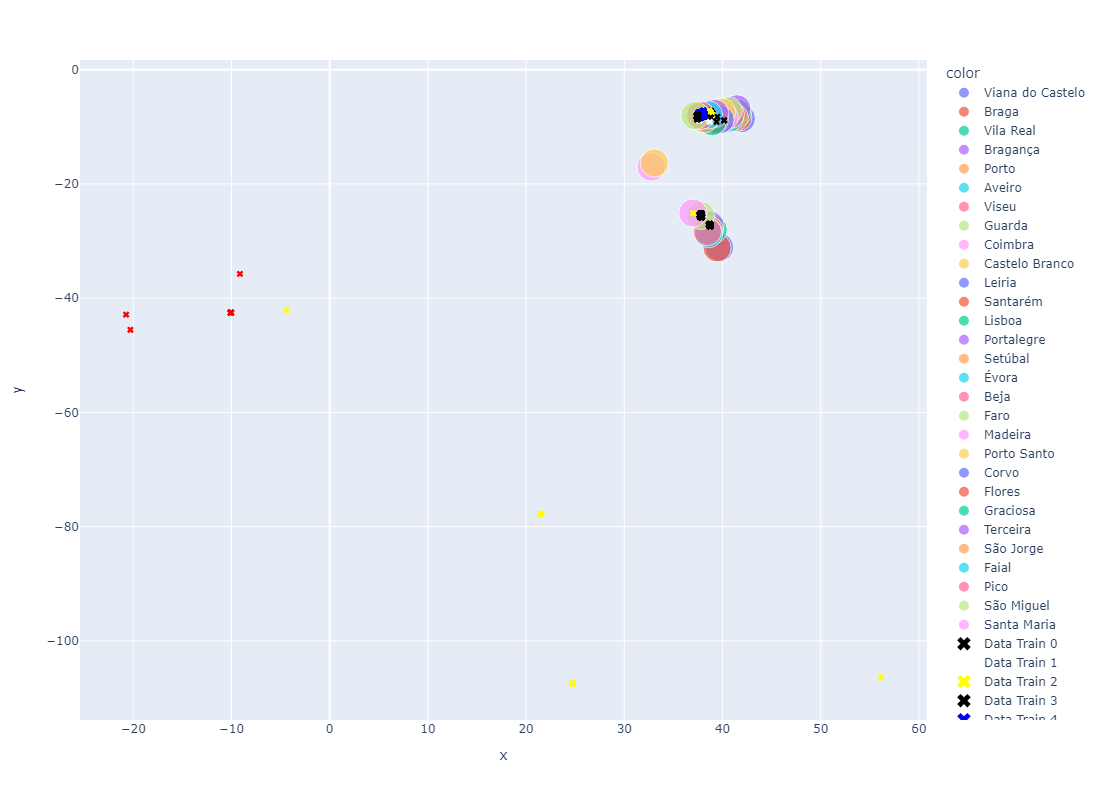

In [6]:
# Visualização 

# Obter lat e long para perceber se os dados que cada centroide têm  
def data_por_cent(X_train):
    centros = X_train['Centroide'].unique()
    latitude, longitude = [], []
    for c in centros:
        lat, log = [], []
        for i in X_train['ID']:
            if X_train['Centroide'][i] == c:
                lat.append(X_train['latitude'][i])
                log.append(X_train['longitude'][i]) 
        latitude.append(lat)
        longitude.append(log)     
    return centros, latitude, longitude

centros, latitude, longitude = data_por_cent(X)

# Criar tamanho ds centroides
distrito['size'] =[10] * 29

def viz_kmeans(distrito, centros, latitude, longitude):
    color = ['black', 'white', 'yellow', 'black', 'blue', 'black','black', 'red', 'yellow', 'black','black', 'white', 'yellow' ] # qnd tivermos + dados tenho de meter 29 cores
    fig = px.scatter(x = distrito['latitude'], y = distrito['longitude'], color = distrito['Distrito'], size = distrito['size'])
    for i in range(len(centros)):
        fig.add_scatter(x =latitude[i] , y=longitude[i], mode='markers', name=f'Data Train {i}',  marker=dict(color=color[i], symbol="x"))
    fig.update_layout(autosize=False,width=1000,height=800)
    fig.show()
viz_kmeans(distrito, centros, latitude, longitude)



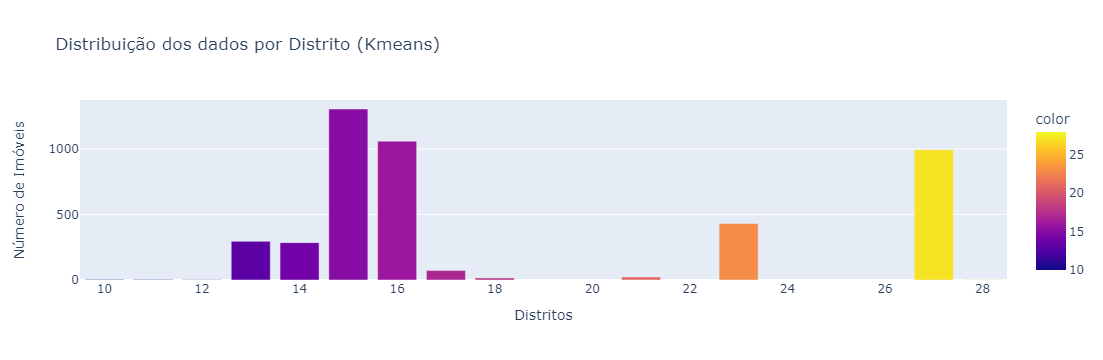

In [40]:
# Ver a distribuição dos dados por cluster aka distrito 
def distr_data_distrito(X_train): 
    col = ['Centroide']
    for nome in col: 
        output = []
        names = X_train[nome].unique()
        for i in X_train[nome].unique():
            bt2 = X_train[nome].value_counts()[i]
            output.append(bt2)
        fig = px.bar(X_train, x=names, y=output, color = names ,color_discrete_sequence= px.colors.qualitative.Pastel2, title= f'Distribuição dos dados por Distrito (Kmeans)')
        fig.update_xaxes(title_text='Distritos')
        fig.update_yaxes(title_text='Número de Imóveis')
        fig.show()

distr_data_distrito(X)

### Criar dataframe para cada cluster aka distrito

### Info relevante para comparação: 
- built_in
- tipology
- amenities
- m2
- m2_util
- energetic_efficiency
- house_type
- latitude_norm
- longitude_norm

In [41]:
# Obter os id dos imoveis de cada cluster 
def imo_cluster_id(X_train, id_cluster):
    conj_i = []
    for i in X_train['ID']:
        if X_train['Centroide'].loc[i] == id_cluster: 
            conj_i.append(i)
    return conj_i

# Criar dataframe para cada cluster 
def df_distrito(X_train, id_cluster): 
    ids =  imo_cluster_id(X_train, id_cluster)
    df = X_train.loc[ids, ['built_in', 'tipology', 'amenities', 'm2', 'm2_util', 'energetic_efficiency', 'house_type','latitude_norm', 'longitude_norm']]
    return df

# Criar dataframe para cada output de cluster 
def df_distrito_out(X, y, id_cluster): 
    ids =  imo_cluster_id(X, id_cluster)
    df = y.loc[ids, ['Price_norm', 'Price_Real']]
    return df


# DataFrame de cada cluster (input e output)

df_0 = df_distrito(X, 0)
df_0_y = df_distrito_out(X, y, 0)

df_1 = df_distrito(X, 1)
df_1_y = df_distrito_out(X, y, 1)

df_2 = df_distrito(X, 2)
df_2_y = df_distrito_out(X, y, 2)

df_3 = df_distrito(X, 3)
df_3_y = df_distrito_out(X, y, 3)

df_4 = df_distrito(X, 4)
df_4_y = df_distrito_out(X, y, 4)

df_5 = df_distrito(X, 5)
df_5_y = df_distrito_out(X, y, 5)

df_6 = df_distrito(X, 6)
df_6_y = df_distrito_out(X, y, 6)

df_7 = df_distrito(X, 7)
df_7_y = df_distrito_out(X, y, 7)

df_8 = df_distrito(X, 8)
df_8_y = df_distrito_out(X, y, 8)

df_9 = df_distrito(X, 9)
df_9_y = df_distrito_out(X, y, 9)

df_10 = df_distrito(X, 10)
df_10_y = df_distrito_out(X, y, 10)

df_11 = df_distrito(X, 11)
df_11_y = df_distrito_out(X, y, 11)

df_12 = df_distrito(X, 12)
df_12_y = df_distrito_out(X, y, 12)

df_13 = df_distrito(X, 13)
df_13_y = df_distrito_out(X, y, 13)

df_14 = df_distrito(X, 14)
df_14_y = df_distrito_out(X, y, 14)

df_15 = df_distrito(X, 15)
df_15_y = df_distrito_out(X, y, 15)

df_16 = df_distrito(X, 16)
df_16_y = df_distrito_out(X, y, 16)

df_17 = df_distrito(X, 17)
df_17_y = df_distrito_out(X, y, 17)

df_18 = df_distrito(X, 18)
df_18_y = df_distrito_out(X, y, 18)

df_19 = df_distrito(X, 19)
df_19_y = df_distrito_out(X, y, 19)

df_20 = df_distrito(X, 20)
df_20_y = df_distrito_out(X, y, 20)

df_21 = df_distrito(X, 21)
df_21_y = df_distrito_out(X, y, 21)

df_22 = df_distrito(X, 22)
df_22_y = df_distrito_out(X, y, 22)

df_23 = df_distrito(X, 23)
df_23_y = df_distrito_out(X, y, 23)

df_24 = df_distrito(X, 24)
df_24_y = df_distrito_out(X, y, 24)

df_25 = df_distrito(X, 25)
df_25_y = df_distrito_out(X, y, 25)

df_26 = df_distrito(X, 26)
df_26_y = df_distrito_out(X, y, 26)

df_27 = df_distrito(X, 27)
df_27_y = df_distrito_out(X, y, 27)

df_28 = df_distrito(X, 28)
df_28_y = df_distrito_out(X, y, 28)

In [42]:
# transformar sub df em csv
#df_27.to_csv("df_27_d.csv")
#df_27_y.to_csv("df_27_y_d.csv")

# Treinar Modelos para cluster --> 13, 14, 15, 16, 23, 27
- 13: Portalegre
- 14: Setubal
- 15: Evora
- 16: Beja
- 23: Terceira
- 27: São Miguel

## ATENÇÃO VARIÁVEIS QUE ESTÃO A SER USADAS: 
- 'tipology',
- 'amenities',
- 'built_in',
- 'energetic_efficiency',
- 'house_type'